# Single-Region Quadrant & Feature Distribution Analysis

Focused single-region validation notebook for **Quadrant Analysis** and **Feature Distribution / JS Divergence** plots and tables:
1. **Setup & Data Loading**: Load configuration, split manifest, best fold models, and pileup-corrected $T(\mu)$ thresholds.
2. **Quadrant Analysis Suite**: Model vs. Athena Cut, Pileup-Corrected $T(\mu)$ vs. Athena Cut, Hard Cut vs. $T(\mu)$, and Model 1 vs. Model 2.
3. **Feature Distributions & JS Divergence Analysis**: Hard-cut and pileup-corrected $T(\mu)$ variable distributions for Photons (Signal) and Jet Leak (Background).

<a id="sec-1"></a>
## 1. Setup, Data Loading & Holdout Partition (`SplitManifest`)

<a id="sec-1-1"></a>
### 1.1 Environment & Imports

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Resolve repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
import mplhep as mh

mh.style.use("ATLAS")

from src.Parser.NeuralRingerTrainerConfiguration import NeuralRingerTrainerConfiguration
from src.core.Trainers.NeuralRingerTrainer import NeuralRingerTrainer
from src.core.Datasets.SplitManifest import SplitManifest
from src.core.Validation.ResultAggregator import ResultAggregator
from src.core.Validation.HoldoutEvaluator import HoldoutEvaluator, HoldoutEvaluationResult
from src.core.Validation.QuadrantAnalyzer import (
    QuadrantAnalyzer,
    RegionalQuadrantResult,
    StrategyMetrics,
)
from src.core.Validation.PileupAnalyzer import PileupAnalyzer
from src.core.Validation.PileupThresholdCalibrator import (
    PileupThresholdCalibrator,
    OperatingPointCalibration,
)
from src.core.Validation.DistributionComparator import DistributionComparator
from src.core.Plotting.FeatureDistributionPlotter import FeatureDistributionPlotter
from src.core.Plotting.QuadrantPlotter import QuadrantPlotter
from src.core.Plotting.Localization import PlotTranslator
from src.utils import (
    get_et_eta,
    save_table,
    extract_feature_values,
)

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__}, CUDA available: {torch.cuda.is_available()}")

Project root: /eos/home-i04/p/pmourafr/egamma_master
PyTorch version: 2.10.0, CUDA available: True


<a id="sec-1-2"></a>
### 1.2 Centralized Configuration Constants
All parameters, model paths, operating points, and region selections are defined below:

In [2]:
# --- Target Kinematic Region ---
TARGET_ET: int = 1
TARGET_ETA: int = 1
REGION_KEY: str = f"et_{TARGET_ET}_eta_{TARGET_ETA}"

# --- Validation & Operating Point Constants ---
TARGET_PD: float = 0.812923                                                               # <<<<<<<<<<<<<<<< Parameter
EFFICIENCIES_CSV: Path | None = None
THRESHOLD_MODE: str = "calibrated"  # 'calibrated' for target PD cut, 'default' for 0.5 threshold
WORKING_POINT: str = "loose"        # Athena fast photon cut: 'loose', 'medium', 'tight'
LANGUAGE: str = PlotTranslator.validate_language("pt")
PLOT_FORMAT: str = "pdf"            # 'png' or 'pdf'
LOG_Y_SECTION_6: bool = True        # Enable logarithmic Y-axis scale for feature distribution plots


EVAL_PILEUP_WP: str = "Baseline"

# --- Model 1 (Primary Model) Paths ---
CONFIG_PATH_1: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml"
RESULTS_PATH_1: Path = PROJECT_ROOT / "results/config_nameModelV9_HighBatch_100Rings_id20261105222012"
MODEL_1_ALIAS: str = "Model V9 (100 Rings)"

# --- Model 2 (Secondary Comparison Model) ---
ENABLE_MODEL2_COMPARISON: bool = True
CONFIG_PATH_2: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_50Rings.yaml"
RESULTS_PATH_2: Path = PROJECT_ROOT / "results/config_nameModelV9_HighBatch_50Rings_id20261109122259"
MODEL_2_ALIAS: str = "Model V9 (50 Rings)"

ATHENA_ALIAS: str = f"Athena {WORKING_POINT.capitalize()} Cut"

# --- Pileup Calibration Constants ---
BINS_MU: int = 10
N_BOOTSTRAPS_PILEUP: int = 100
PILEUP_WORKING_POINTS: dict[str, float] = {
    "Baseline": TARGET_PD,
}
OUTPUT_FOLDER_NAME: str = f"SingleRegionValidation_{RESULTS_PATH_1.name}_{REGION_KEY}"
OUTPUT_DIR: Path = PROJECT_ROOT / "Plots" / OUTPUT_FOLDER_NAME


# --- Common Data & Output Directories ---
DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = RESULTS_PATH_1.parent / "split_manifest.json"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR: Path = OUTPUT_DIR / "Tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Plot Language:        {LANGUAGE}")
print(f"Target Region:        {REGION_KEY} (ET={TARGET_ET}, ETA={TARGET_ETA})")
print(f"Primary Config:       {CONFIG_PATH_1}")
print(f"Primary Results:      {RESULTS_PATH_1}")
print(f"Output Directory:     {OUTPUT_DIR}")
print(f"Tables Directory:     {TABLES_DIR}")
print(f"Target Efficiency:    {TARGET_PD * 100:.2f}%")
print(f"Athena Working Point: {WORKING_POINT.capitalize()}")
print(f"Model 1 Alias:        {MODEL_1_ALIAS}")
print(f"Model 2 Alias:        {MODEL_2_ALIAS}")
print(f"Athena Alias:         {ATHENA_ALIAS}")

FEATURES_TO_PLOT: list[str] = [
    "trig_L2_calo_et",
    "trig_L2_calo_eta",
    "trig_L2_calo_phi",
    "trig_L2_calo_e237",
    "trig_L2_calo_e277",
    "trig_L2_calo_fracs1",
    "trig_L2_calo_weta2",
    "trig_L2_calo_ehad1",
    "trig_L2_calo_emaxs1",
    "trig_L2_calo_e2tsts1",
    "trig_L2_calo_wstot",
    "Eratio",
]
print(f"Features configured:  {len(FEATURES_TO_PLOT)} variables")

Plot Language:        pt
Target Region:        et_1_eta_1 (ET=1, ETA=1)
Primary Config:       /eos/home-i04/p/pmourafr/egamma_master/config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml
Primary Results:      /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV9_HighBatch_100Rings_id20261105222012
Output Directory:     /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1
Tables Directory:     /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1/Tables
Target Efficiency:    81.29%
Athena Working Point: Loose
Model 1 Alias:        Model V9 (100 Rings)
Model 2 Alias:        Model V9 (50 Rings)
Athena Alias:         Athena Loose Cut
Features configured:  12 variables


<a id="sec-1-3"></a>
### 1.3 Dataset Loading, `SplitManifest` Partitioning & Feature Validation
Loads dataset samples for the configured region, retrieves deterministic train/validation/test indices from [`SplitManifest`](file:///home/pmourafr/egamma_master/src/core/Datasets/SplitManifest.py), and validates configured shower-shape features:

In [3]:
with open(CONFIG_PATH_1, "r") as f:
    config_dict_1 = yaml.safe_load(f)

if DATA_PATH.exists():
    config_dict_1["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)

config_1 = NeuralRingerTrainerConfiguration.model_validate(config_dict_1)
trainer_1 = NeuralRingerTrainer(config_1)
full_dataset = trainer_1.full_dataset
feature_names = full_dataset.feature_names

# Locate dataset index matching TARGET_ET and TARGET_ETA
region_file_idx = None
for idx, path_str in enumerate(full_dataset.file_paths):
    iet, ieta = get_et_eta(path_str)
    if iet == TARGET_ET and ieta == TARGET_ETA:
        region_file_idx = idx
        break

if region_file_idx is None:
    raise FileNotFoundError(f"No dataset file matching et={TARGET_ET}, eta={TARGET_ETA} in {DATA_PATH}")

raw_features, raw_labels, region_file_path = full_dataset[region_file_idx]
print(f"Loaded dataset file: {region_file_path}")
print(f"Total events in region: {len(raw_labels):,}")

# Load deterministic test split and K-fold partitions from SplitManifest
manifest = SplitManifest(str(MANIFEST_PATH))
if not manifest.exists():
    raise FileNotFoundError(f"Manifest not found at {MANIFEST_PATH}")

manifest.load()
test_indices, train_folds = manifest.get_region_splits(REGION_KEY)
test_indices = np.array(test_indices, dtype=int)

all_indices = np.arange(len(raw_labels))
train_val_mask = ~np.isin(all_indices, test_indices)

test_features = raw_features[test_indices]
test_labels = raw_labels[test_indices]
train_val_labels = raw_labels[train_val_mask]

# Summarize class balance across partitions
test_sig = int(np.sum(test_labels == 1))
test_bg = int(np.sum(test_labels == 0))
total_test = len(test_labels)

train_sig = int(np.sum(train_val_labels == 1))
train_bg = int(np.sum(train_val_labels == 0))
total_train = len(train_val_labels)

summary_df = pd.DataFrame([
    {
        "Partition": "Holdout Test Set",
        "Signal (Photons)": test_sig,
        "Background (Jets)": test_bg,
        "Total Events": total_test,
        "Signal Fraction": f"{test_sig / total_test:.2%}",
        "Background Fraction": f"{test_bg / total_test:.2%}",
    },
    {
        "Partition": "Train / Val Set",
        "Signal (Photons)": train_sig,
        "Background (Jets)": train_bg,
        "Total Events": total_train,
        "Signal Fraction": f"{train_sig / total_train:.2%}",
        "Background Fraction": f"{train_bg / total_train:.2%}",
    },
    {
        "Partition": "Full Region Data",
        "Signal (Photons)": test_sig + train_sig,
        "Background (Jets)": test_bg + train_bg,
        "Total Events": total_test + total_train,
        "Signal Fraction": f"{(test_sig + train_sig) / (total_test + total_train):.2%}",
        "Background Fraction": f"{(test_bg + train_bg) / (total_test + total_train):.2%}",
    },
])
display(summary_df)
save_table(summary_df, TABLES_DIR, REGION_KEY, "class_distribution_summary")

valid_features_to_plot = []
for f in FEATURES_TO_PLOT:
    try:
        _ = extract_feature_values(test_features[:5], feature_names, f)
        valid_features_to_plot.append(f)
    except KeyError as e:
        print(f"Skipping {f}: {e}")

Loaded dataset file: /eos/home-i04/p/pmourafr/egamma_master/data/consolidated/consolidated.et1.eta1.npz
Total events in region: 143,780


,Partition,Signal (Photons),Background (Jets),Total Events,Signal Fraction,Background Fraction
0,Holdout Test Set,3994,10384,14378,27.78%,72.22%
1,Train / Val Set,35938,93464,129402,27.77%,72.23%
2,Full Region Data,39932,103848,143780,27.77%,72.23%


<a id="sec-2"></a>
## 2. Model Evaluation & Pileup Threshold Calibration ($T(\mu)$)

<a id="sec-2-1"></a>
### 2.1 Model 1 Checkpoint Aggregation & Holdout Evaluation
Scans fold files using [`ResultAggregator`](file:///home/pmourafr/egamma_master/src/core/Validation/ResultAggregator.py), extracts the best SP checkpoint, and evaluates holdout test metrics via [`HoldoutEvaluator`](file:///home/pmourafr/egamma_master/src/core/Validation/HoldoutEvaluator.py):

In [4]:
aggregator_1 = ResultAggregator(RESULTS_PATH_1)
if not aggregator_1.has_region(TARGET_ET, TARGET_ETA):
    raise RuntimeError(f"No result records found in {RESULTS_PATH_1} for iet{TARGET_ET}.ieta{TARGET_ETA}")

best_model_1, best_rep_1, mean_sp_1, std_sp_1 = aggregator_1.get_best_model_for_region(TARGET_ET, TARGET_ETA)
print(f"Model 1 Best SP for {REGION_KEY}: {best_model_1['best_sp_value']:.4f} (Region Mean: {mean_sp_1:.4f} ± {std_sp_1:.4f})")
print(f"Best Fold: {best_model_1.get('fold')}, Best Init: {best_rep_1}")

model_1 = trainer_1.factory.create_model()
model_1.load_state_dict(best_model_1["best_weights"])
model_1.to(trainer_1.device)
model_1.eval()

evaluator = HoldoutEvaluator(default_target_pd=TARGET_PD)

ring_column_indices = full_dataset.ring_column_indices
if ring_column_indices is None:
    ring_column_indices = full_dataset.indexes

eval_result_1 = evaluator.evaluate(
    model=model_1,
    data=raw_features,
    target=raw_labels,
    test_indices=test_indices,
    ring_column_indices=ring_column_indices,
    device=trainer_1.device,
    target_pd=TARGET_PD,
)

print(f"\nValidation Holdout Performance for {MODEL_1_ALIAS} ({REGION_KEY}):")
print(f"  Target Detection Efficiency (PD):   {eval_result_1.pd:.4f} ({eval_result_1.pd:.2%})")
print(f"  Calibrated Operating Cut (Th):       {eval_result_1.threshold:.4f}")
print(f"  False Alarm Rate (PF):               {eval_result_1.pf:.4f} ({eval_result_1.pf:.2%})")
print(f"  SP Index at Target Cut:              {eval_result_1.sp:.4f}")
print(f"  Area Under ROC Curve (AUC):          {eval_result_1.auc:.4f}")


Skipping unreadable result file /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV9_HighBatch_100Rings_id20261105222012/repeat1.fold_idx3.iet4.ieta0.pkl: Ran out of input


Model 1 Best SP for et_1_eta_1: 0.8476 (Region Mean: 0.8423 ± 0.0039)
Best Fold: 6, Best Init: 3

Validation Holdout Performance for Model V9 (100 Rings) (et_1_eta_1):
  Target Detection Efficiency (PD):   0.8130 (81.30%)
  Calibrated Operating Cut (Th):       0.2640
  False Alarm Rate (PF):               0.1393 (13.93%)
  SP Index at Target Cut:              0.8367
  Area Under ROC Curve (AUC):          0.9026


<a id="sec-2-2"></a>
### 2.2 Model 1 Pileup-Dependent Dynamic Threshold Calibration ($T(\mu) = a\mu + b$)
Calibrates pileup-dependent decision boundaries on the training/validation partition using [`PileupThresholdCalibrator`](file:///home/pmourafr/egamma_master/src/core/Validation/PileupThresholdCalibrator.py) and applies $T(\mu)$ to holdout test logits:

In [5]:
best_fold_1 = int(best_model_1.get("fold", 0))
train_indices_1, val_indices_1 = train_folds[best_fold_1]
calib_indices_1 = np.concatenate([train_indices_1, val_indices_1])

calib_features_1 = raw_features[calib_indices_1]
calib_labels_1 = raw_labels[calib_indices_1]
calib_ring_features_1 = calib_features_1[:, ring_column_indices]

logits_calib_1 = HoldoutEvaluator.predict_logits(model_1, calib_ring_features_1, trainer_1.device)
mu_calib_1 = PileupAnalyzer.extract_feature(calib_features_1, feature_names, "avgmu")
mu_test = PileupAnalyzer.extract_feature(test_features, feature_names, "avgmu")

signal_calib_mask_1 = calib_labels_1 == 1
mu_signal_calib_1 = mu_calib_1[signal_calib_mask_1]
logits_signal_calib_1 = logits_calib_1[signal_calib_mask_1]

calibrator_1 = PileupThresholdCalibrator(
    bins_mu=BINS_MU,
    n_bootstraps=N_BOOTSTRAPS_PILEUP,
    random_seed=42,
)
dist_2d_1 = calibrator_1.compute_2d_distribution(mu_signal_calib_1, logits_signal_calib_1, bins=35)
calibrations_1 = calibrator_1.calibrate_multiple_points(mu_signal_calib_1, logits_signal_calib_1, PILEUP_WORKING_POINTS)
cal_1 = calibrations_1[EVAL_PILEUP_WP]

preds_pileup_1 = PileupThresholdCalibrator.apply_threshold(
    eval_result_1.predicted_logits, mu_test, cal_1.slope, cal_1.intercept
)

sign_str_1 = "+" if cal_1.intercept >= 0 else "-"
print(f"Model 1 Pileup Calibration for WP '{EVAL_PILEUP_WP}':")
print(f"  Slope (a):     {cal_1.slope:.4f}")
print(f"  Intercept (b): {cal_1.intercept:.4f}")
print(f"  R^2:           {cal_1.r_squared:.4f}")
print(f"  Boundary:      T(mu) = {cal_1.slope:.4f}*mu {sign_str_1} {abs(cal_1.intercept):.4f}")


Model 1 Pileup Calibration for WP 'Baseline':
  Slope (a):     -0.0027
  Intercept (b): -0.9078
  R^2:           0.3181
  Boundary:      T(mu) = -0.0027*mu - 0.9078


<a id="sec-2-3"></a>
### 2.3 Model 1 Operating Points & Efficiency Table with Uncertainties
Consolidates operational metrics (Detection Efficiency, False Alarm, Background Rejection, Accuracy, and SP index) with binomial and error-propagated uncertainties for the best training SP knee point, calibrated hard cut ($Th_{\text{target}}$), and pileup-corrected threshold cut ($T(\mu)$):

In [6]:
val_labels_1 = raw_labels[val_indices_1]
n_val_sig = int(np.sum(val_labels_1 == 1))
n_val_bg = int(np.sum(val_labels_1 == 0))
n_val_total = len(val_labels_1)

tp_knee_1 = int(round(best_model_1["best_pd_value"] * n_val_sig))
fn_knee_1 = n_val_sig - tp_knee_1
fp_knee_1 = int(round(best_model_1["best_fa_value"] * n_val_bg))
tn_knee_1 = n_val_bg - fp_knee_1

m_knee = StrategyMetrics(
    pd=float(best_model_1["best_pd_value"]),
    pf=float(best_model_1["best_fa_value"]),
    sp=float(best_model_1["best_sp_value"]),
    eff=float((tp_knee_1 + tn_knee_1) / n_val_total) if n_val_total > 0 else 0.0,
    tp=tp_knee_1,
    fp=fp_knee_1,
    tn=tn_knee_1,
    fn=fn_knee_1,
    total=n_val_total,
)

m_cal = StrategyMetrics.from_predictions(eval_result_1.predictions_calibrated_cut, eval_result_1.holdout_labels)
m_pileup_1 = StrategyMetrics.from_predictions(preds_pileup_1, eval_result_1.holdout_labels)

efficiency_table = pd.DataFrame([
    {
        "Operating Point": f"Best Training SP Knee Point ({best_model_1['best_sp_value']:.4f})",
        "Decision Threshold": "Knee Point",
        "PD (Signal Eff)": m_knee.pd,
        "PD Uncertainty": m_knee.pd_uncertainty,
        "PF (Fake Rate)": m_knee.pf,
        "PF Uncertainty": m_knee.pf_uncertainty,
        "Background Rejection": m_knee.bg_eff,
        "Background Rejection Uncertainty": m_knee.bg_eff_uncertainty,
        "Accuracy (Eff)": m_knee.eff,
        "Accuracy Uncertainty": m_knee.eff_uncertainty,
        "SP Index": m_knee.sp,
        "SP Index Uncertainty": m_knee.sp_uncertainty,
        "TP": m_knee.tp,
        "FP": m_knee.fp,
        "TN": m_knee.tn,
        "FN": m_knee.fn,
    },
    {
        "Operating Point": f"Calibrated Hard Cut (Target PD: {TARGET_PD*100:.2f}%)",
        "Decision Threshold": f"{eval_result_1.threshold:.4f}",
        "PD (Signal Eff)": m_cal.pd,
        "PD Uncertainty": m_cal.pd_uncertainty,
        "PF (Fake Rate)": m_cal.pf,
        "PF Uncertainty": m_cal.pf_uncertainty,
        "Background Rejection": m_cal.bg_eff,
        "Background Rejection Uncertainty": m_cal.bg_eff_uncertainty,
        "Accuracy (Eff)": m_cal.eff,
        "Accuracy Uncertainty": m_cal.eff_uncertainty,
        "SP Index": m_cal.sp,
        "SP Index Uncertainty": m_cal.sp_uncertainty,
        "TP": m_cal.tp,
        "FP": m_cal.fp,
        "TN": m_cal.tn,
        "FN": m_cal.fn,
    },
    {
        "Operating Point": f"Pileup-Corrected Cut T(mu) (Target PD: {cal_1.target_pd*100:.2f}%)",
        "Decision Threshold": f"T(mu)={cal_1.slope:.4f}*mu{sign_str_1}{abs(cal_1.intercept):.4f}",
        "PD (Signal Eff)": m_pileup_1.pd,
        "PD Uncertainty": m_pileup_1.pd_uncertainty,
        "PF (Fake Rate)": m_pileup_1.pf,
        "PF Uncertainty": m_pileup_1.pf_uncertainty,
        "Background Rejection": m_pileup_1.bg_eff,
        "Background Rejection Uncertainty": m_pileup_1.bg_eff_uncertainty,
        "Accuracy (Eff)": m_pileup_1.eff,
        "Accuracy Uncertainty": m_pileup_1.eff_uncertainty,
        "SP Index": m_pileup_1.sp,
        "SP Index Uncertainty": m_pileup_1.sp_uncertainty,
        "TP": m_pileup_1.tp,
        "FP": m_pileup_1.fp,
        "TN": m_pileup_1.tn,
        "FN": m_pileup_1.fn,
    },
])
display(efficiency_table)
save_table(efficiency_table, TABLES_DIR, REGION_KEY, "operating_points_efficiency")


,Operating Point,Decision Threshold,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,Background Rejection,Background Rejection Uncertainty,Accuracy (Eff),Accuracy Uncertainty,SP Index,SP Index Uncertainty,TP,FP,TN,FN
0,Best Training SP Knee Point (0.8476),Knee Point,0.812923,0.006171,0.116996,0.003154,0.883004,0.003154,0.863542,0.002863,0.847601,0.003509,3246,1215,9170,747
1,Calibrated Hard Cut (Target PD: 81.29%),0.2640,0.812969,0.006170,0.139253,0.003397,0.860747,0.003397,0.847475,0.002998,0.836688,0.003550,3247,1446,8938,747
2,Pileup-Corrected Cut T(mu) (Target PD: 81.29%),T(mu)=-0.0027*mu-0.9078,0.814972,0.006144,0.143105,0.003436,0.856895,0.003436,0.845250,0.003016,0.835802,0.003544,3255,1486,8898,739


PosixPath('/eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1/Tables/et_1_eta_1_operating_points_efficiency.csv')

<a id="sec-2-4"></a>
### 2.4 Model 2 Holdout Evaluation & Pileup Calibration (Optional Comparison Model)
When `ENABLE_MODEL2_COMPARISON` is active, loads the secondary model checkpoint and evaluates both its static threshold and dynamic pileup-corrected $T(\mu)$ predictions:

In [7]:
eval_res_2 = None
preds_2 = None
cal_2 = None
preds_pileup_2 = None

if ENABLE_MODEL2_COMPARISON and RESULTS_PATH_2.exists():
    try:
        aggregator_2 = ResultAggregator(RESULTS_PATH_2)
        if aggregator_2.has_region(TARGET_ET, TARGET_ETA):
            best_model_2, best_rep_2, mean_sp_2, std_sp_2 = aggregator_2.get_best_model_for_region(TARGET_ET, TARGET_ETA)
            print(f"{MODEL_2_ALIAS} Best SP for {REGION_KEY}: {best_model_2['best_sp_value']:.4f} (Mean: {mean_sp_2:.4f} ± {std_sp_2:.4f})")

            with open(CONFIG_PATH_2, "r") as f2:
                config_dict_2 = yaml.safe_load(f2)
            if DATA_PATH.exists():
                config_dict_2["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)
            config_2 = NeuralRingerTrainerConfiguration.model_validate(config_dict_2)
            trainer_2 = NeuralRingerTrainer(config_2)

            region_file_idx_2 = None
            for idx_f, path_str in enumerate(trainer_2.full_dataset.file_paths):
                iet_f, ieta_f = get_et_eta(path_str)
                if iet_f == TARGET_ET and ieta_f == TARGET_ETA:
                    region_file_idx_2 = idx_f
                    break

            if region_file_idx_2 is not None:
                data_2, target_2, _ = trainer_2.full_dataset[region_file_idx_2]
                ring_indices_2 = trainer_2.full_dataset.ring_column_indices
                if ring_indices_2 is None:
                    ring_indices_2 = trainer_2.full_dataset.indexes

                model_2 = trainer_2.factory.create_model()
                model_2.load_state_dict(best_model_2["best_weights"])
                model_2.to(trainer_1.device)
                model_2.eval()

                eval_res_2 = evaluator.evaluate(
                    model=model_2,
                    data=data_2,
                    target=target_2,
                    test_indices=test_indices,
                    ring_column_indices=ring_indices_2,
                    device=trainer_1.device,
                    target_pd=TARGET_PD,
                )
                preds_2 = (
                    eval_res_2.predictions_calibrated_cut
                    if THRESHOLD_MODE == "calibrated"
                    else eval_res_2.predictions_default_threshold
                )

                # Calibrate Model 2 pileup threshold T(mu)
                best_fold_2 = int(best_model_2.get("fold", 0))
                train_indices_2, val_indices_2 = train_folds[best_fold_2]
                calib_indices_2 = np.concatenate([train_indices_2, val_indices_2])
                calib_features_2 = data_2[calib_indices_2]
                calib_labels_2 = target_2[calib_indices_2]
                calib_ring_features_2 = calib_features_2[:, ring_indices_2]

                logits_calib_2 = HoldoutEvaluator.predict_logits(model_2, calib_ring_features_2, trainer_1.device)
                mu_calib_2 = PileupAnalyzer.extract_feature(calib_features_2, trainer_2.full_dataset.feature_names, "avgmu")
                signal_mask_2 = calib_labels_2 == 1

                calibrations_2 = calibrator_1.calibrate_multiple_points(
                    mu_calib_2[signal_mask_2], logits_calib_2[signal_mask_2], PILEUP_WORKING_POINTS
                )
                cal_2 = calibrations_2[EVAL_PILEUP_WP]
                preds_pileup_2 = PileupThresholdCalibrator.apply_threshold(
                    eval_res_2.predicted_logits, mu_test, cal_2.slope, cal_2.intercept
                )
                sign_str_2 = "+" if cal_2.intercept >= 0 else "-"
                print(f"{MODEL_2_ALIAS} Pileup Boundary: T(mu) = {cal_2.slope:.4f}*mu {sign_str_2} {abs(cal_2.intercept):.4f}")
    except Exception as e:
        print(f"Note: Model 2 evaluation skipped: {e}")


Model V9 (50 Rings) Best SP for et_1_eta_1: 0.8432 (Mean: 0.8380 ± 0.0041)
Model V9 (50 Rings) Pileup Boundary: T(mu) = -0.0015*mu - 0.9537


<a id="sec-4"></a>
## 4. Quadrant Analysis Suite

<a id="sec-4-1"></a>
### 4.1 Model 1 (Hard Cut) vs. Athena Trigger Linear Cuts
Compares holdout predictions of Model 1 (static threshold) against the cut-based Athena baseline using [`QuadrantAnalyzer`](file:///home/pmourafr/egamma_master/src/core/Validation/QuadrantAnalyzer.py) in `model_vs_cut` mode:

In [8]:
quadrant_plotter = QuadrantPlotter(language=LANGUAGE)


def render_quadrant_section(
    res: RegionalQuadrantResult,
    subdir_name: str,
    table_prefix: str,
    strategy_col: str = "Strategy",
) -> None:
    """Displays and exports strategy metrics, quadrant counts, and quadrant plots."""
    quadrant_dir = OUTPUT_DIR / subdir_name
    quadrant_dir.mkdir(parents=True, exist_ok=True)

    s1 = res.metrics_strategy1
    s2 = res.metrics_strategy2
    qm = res.overall_metrics

    strategy_df = pd.DataFrame([
        {
            strategy_col: res.strategy1_name,
            "PD (Signal Eff)": s1.pd,
            "PD Uncertainty": s1.pd_uncertainty,
            "PF (Fake Rate)": s1.pf,
            "PF Uncertainty": s1.pf_uncertainty,
            "SP Index": s1.sp,
            "SP Index Uncertainty": s1.sp_uncertainty,
            "Accuracy": s1.eff,
            "Accuracy Uncertainty": s1.eff_uncertainty,
        },
        {
            strategy_col: res.strategy2_name,
            "PD (Signal Eff)": s2.pd,
            "PD Uncertainty": s2.pd_uncertainty,
            "PF (Fake Rate)": s2.pf,
            "PF Uncertainty": s2.pf_uncertainty,
            "SP Index": s2.sp,
            "SP Index Uncertainty": s2.sp_uncertainty,
            "Accuracy": s2.eff,
            "Accuracy Uncertainty": s2.eff_uncertainty,
        },
    ])
    display(strategy_df)
    save_table(strategy_df, TABLES_DIR, REGION_KEY, f"{table_prefix}_strategy_metrics")

    counts_df = pd.DataFrame({
        "Quadrant": [
            "Both Correct",
            f"Only {res.strategy1_name} Correct",
            f"Only {res.strategy2_name} Correct",
            "Both Wrong",
        ],
        "Event Count": [qm.both_correct, qm.model1_only_correct, qm.model2_only_correct, qm.both_wrong],
        "Ratio": [
            f"{qm.both_correct_ratio:.2%}",
            f"{qm.model1_only_correct_ratio:.2%}",
            f"{qm.model2_only_correct_ratio:.2%}",
            f"{qm.both_wrong_ratio:.2%}",
        ],
    })
    print(f"McNemar p-value: {qm.mcnemar_p_value:.3e}")
    display(counts_df)
    save_table(counts_df, TABLES_DIR, REGION_KEY, f"{table_prefix}_quadrant_counts")

    saved_plots = quadrant_plotter.plot([res], quadrant_dir, file_format=PLOT_FORMAT)
    print(f"Generated {sum(len(p) for p in saved_plots.values())} plots under: {quadrant_dir}")


quadrant_cut_analyzer = QuadrantAnalyzer(
    config_path1=str(CONFIG_PATH_1),
    data_path1=str(RESULTS_PATH_1),
    manifest_path=str(MANIFEST_PATH),
    threshold_mode=THRESHOLD_MODE,
    efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
    default_target_pd=TARGET_PD,
    mode="model_vs_cut",
    working_point=WORKING_POINT,
    target_et=TARGET_ET,
    target_eta=TARGET_ETA,
    strategy1_alias=MODEL_1_ALIAS,
    strategy2_alias=ATHENA_ALIAS,
)

cut_results = quadrant_cut_analyzer.run()
if not cut_results:
    raise RuntimeError(f"No quadrant results generated for {REGION_KEY}")

cut_res = cut_results[0]
render_quadrant_section(
    res=cut_res,
    subdir_name="Quadrant_Model_vs_Cut",
    table_prefix=f"model1_vs_cut_{WORKING_POINT}",
)

Skipping unreadable result file /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV9_HighBatch_100Rings_id20261105222012/repeat1.fold_idx3.iet4.ieta0.pkl: Ran out of input


,Strategy,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,SP Index,SP Index Uncertainty,Accuracy,Accuracy Uncertainty
0,Model V9 (100 Rings),0.812969,0.00617,0.139253,0.003397,0.836688,0.003550,0.847475,0.002998
1,Athena Loose Cut,0.777666,0.00658,0.414965,0.004835,0.677921,0.004026,0.638545,0.004007


McNemar p-value: 0.000e+00


,Quadrant,Event Count,Ratio
0,Both Correct,8490,59.05%
1,Only Model V9 (100 Rings) Correct,3695,25.70%
2,Only Athena Loose Cut Correct,691,4.81%
3,Both Wrong,1502,10.45%


Generated 26 plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1/Quadrant_Model_vs_Cut


<a id="sec-4-2"></a>
### 4.2 Model 1 (Pileup-Corrected $T(\mu)$) vs. Athena Trigger Linear Cuts
Benchmarks holdout test performance of Model 1 under the dynamic pileup-calibrated boundary $T(\mu) = a\mu + b$ against the Athena baseline selection:

In [9]:
s1_pileup = StrategyMetrics.from_predictions(preds_pileup_1, test_labels)
s2_athena = cut_res.metrics_strategy2
qm_pileup = QuadrantAnalyzer.compute_quadrant_metrics(preds_pileup_1, cut_res.preds_strategy2, test_labels)

pileup_cut_res = RegionalQuadrantResult(
    iet=TARGET_ET,
    ieta=TARGET_ETA,
    strategy1_name=f"{cut_res.strategy1_name} [T(mu)]",
    strategy2_name=cut_res.strategy2_name,
    metrics_strategy1=s1_pileup,
    metrics_strategy2=s2_athena,
    overall_metrics=qm_pileup,
    signal_metrics=QuadrantAnalyzer.compute_quadrant_metrics(
        preds_pileup_1[test_labels == 1], cut_res.preds_strategy2[test_labels == 1], test_labels[test_labels == 1]
    ),
    background_metrics=QuadrantAnalyzer.compute_quadrant_metrics(
        preds_pileup_1[test_labels == 0], cut_res.preds_strategy2[test_labels == 0], test_labels[test_labels == 0]
    ),
    preds_strategy1=preds_pileup_1,
    preds_strategy2=cut_res.preds_strategy2,
    labels=test_labels,
    threshold_strategy1=cal_1.intercept,
    threshold_strategy2=cut_res.threshold_strategy2,
    showershapes=cut_res.showershapes,
    probs_model1=cut_res.probs_model1,
    probs_model2=cut_res.probs_model2,
    et=cut_res.et,
    eta=cut_res.eta,
)

render_quadrant_section(
    res=pileup_cut_res,
    subdir_name="Quadrant_Model_PileupCorrected_vs_Cut",
    table_prefix=f"model1_pileup_vs_cut_{WORKING_POINT}",
)

,Strategy,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,SP Index,SP Index Uncertainty,Accuracy,Accuracy Uncertainty
0,Model V9 (100 Rings) [T(mu)],0.814972,0.006144,0.143105,0.003436,0.835802,0.003544,0.845250,0.003016
1,Athena Loose Cut,0.777666,0.006580,0.414965,0.004835,0.677921,0.004026,0.638545,0.004007


McNemar p-value: 0.000e+00


,Quadrant,Event Count,Ratio
0,Both Correct,8470,58.91%
1,Only Model V9 (100 Rings) [T(mu)] Correct,3683,25.62%
2,Only Athena Loose Cut Correct,711,4.95%
3,Both Wrong,1514,10.53%


Generated 26 plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1/Quadrant_Model_PileupCorrected_vs_Cut


<a id="sec-4-3"></a>
### 4.3 Model 1 (Hard Cut) vs. Model 1 (Pileup-Corrected $T(\mu)$)
Direct contingency matrix quantifying event migration between the static decision cut and the dynamic pileup-corrected threshold:

In [10]:
s1_hard = cut_res.metrics_strategy1
qm_hard_vs_pileup = QuadrantAnalyzer.compute_quadrant_metrics(cut_res.preds_strategy1, preds_pileup_1, test_labels)

hvp_res = RegionalQuadrantResult(
    iet=TARGET_ET,
    ieta=TARGET_ETA,
    strategy1_name=f"{cut_res.strategy1_name} (Hard Cut)",
    strategy2_name=f"{cut_res.strategy1_name} [T(mu)]",
    metrics_strategy1=s1_hard,
    metrics_strategy2=s1_pileup,
    overall_metrics=qm_hard_vs_pileup,
    signal_metrics=QuadrantAnalyzer.compute_quadrant_metrics(
        cut_res.preds_strategy1[test_labels == 1], preds_pileup_1[test_labels == 1], test_labels[test_labels == 1]
    ),
    background_metrics=QuadrantAnalyzer.compute_quadrant_metrics(
        cut_res.preds_strategy1[test_labels == 0], preds_pileup_1[test_labels == 0], test_labels[test_labels == 0]
    ),
    preds_strategy1=cut_res.preds_strategy1,
    preds_strategy2=preds_pileup_1,
    labels=test_labels,
    threshold_strategy1=cut_res.threshold_strategy1,
    threshold_strategy2=cal_1.intercept,
    showershapes=cut_res.showershapes,
    probs_model1=cut_res.probs_model1,
    probs_model2=cut_res.probs_model1,
    et=cut_res.et,
    eta=cut_res.eta,
)

render_quadrant_section(
    res=hvp_res,
    subdir_name="Quadrant_Model1_HardCut_vs_Pileup",
    table_prefix="model1_hard_cut_vs_pileup",
)

,Strategy,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,SP Index,SP Index Uncertainty,Accuracy,Accuracy Uncertainty
0,Model V9 (100 Rings) (Hard Cut),0.812969,0.006170,0.139253,0.003397,0.836688,0.003550,0.847475,0.002998
1,Model V9 (100 Rings) [T(mu)],0.814972,0.006144,0.143105,0.003436,0.835802,0.003544,0.845250,0.003016


McNemar p-value: 1.357e-04


,Quadrant,Event Count,Ratio
0,Both Correct,12136,84.41%
1,Only Model V9 (100 Rings) (Hard Cut) Correct,49,0.34%
2,Only Model V9 (100 Rings) [T(mu)] Correct,17,0.12%
3,Both Wrong,2176,15.13%


Generated 26 plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1/Quadrant_Model1_HardCut_vs_Pileup


<a id="sec-4-4"></a>
### 4.4 Comparative Analysis: Model 1 vs. Model 2 (Hard Cut)
Executes holdout quadrant benchmarking across both neural architectures under static threshold cuts:

In [11]:
quadrant_m2m_analyzer = QuadrantAnalyzer(
    config_path1=str(CONFIG_PATH_1),
    data_path1=str(RESULTS_PATH_1),
    config_path2=str(CONFIG_PATH_2),
    data_path2=str(RESULTS_PATH_2),
    manifest_path=str(MANIFEST_PATH),
    threshold_mode=THRESHOLD_MODE,
    efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
    default_target_pd=TARGET_PD,
    mode="model_vs_model",
    target_et=TARGET_ET,
    target_eta=TARGET_ETA,
    strategy1_alias=MODEL_1_ALIAS,
    strategy2_alias=MODEL_2_ALIAS,
)

m2m_results = quadrant_m2m_analyzer.run()
if not m2m_results:
    print(f"No comparative results generated for Model 1 vs Model 2 in {REGION_KEY}")
else:
    m2m_res = m2m_results[0]
    render_quadrant_section(
        res=m2m_res,
        subdir_name="Quadrant_Model_vs_Model",
        table_prefix="model1_vs_model2",
        strategy_col="Model",
    )

Skipping unreadable result file /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV9_HighBatch_100Rings_id20261105222012/repeat1.fold_idx3.iet4.ieta0.pkl: Ran out of input


,Model,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,SP Index,SP Index Uncertainty,Accuracy,Accuracy Uncertainty
0,Model V9 (100 Rings),0.812969,0.00617,0.139253,0.003397,0.836688,0.003550,0.847475,0.002998
1,Model V9 (50 Rings),0.812969,0.00617,0.145801,0.003463,0.833457,0.003561,0.842746,0.003036


McNemar p-value: 4.139e-03


,Quadrant,Event Count,Ratio
0,Both Correct,11878,82.61%
1,Only Model V9 (100 Rings) Correct,307,2.14%
2,Only Model V9 (50 Rings) Correct,239,1.66%
3,Both Wrong,1954,13.59%


Generated 26 plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1/Quadrant_Model_vs_Model


<a id="sec-4-5"></a>
### 4.5 Comparative Analysis: Model 1 $[T(\mu)]$ vs. Model 2 $[T(\mu)]$
Benchmarks holdout test predictions of Model 1 against Model 2 under their respective dynamic pileup-calibrated decision functions:

In [12]:
if ENABLE_MODEL2_COMPARISON and preds_pileup_2 is not None:
    s1_m2m_p = StrategyMetrics.from_predictions(preds_pileup_1, test_labels)
    s2_m2m_p = StrategyMetrics.from_predictions(preds_pileup_2, test_labels)
    qm_m2m_p = QuadrantAnalyzer.compute_quadrant_metrics(preds_pileup_1, preds_pileup_2, test_labels)

    m2m_pileup_res = RegionalQuadrantResult(
        iet=TARGET_ET,
        ieta=TARGET_ETA,
        strategy1_name=f"{MODEL_1_ALIAS} [T(mu)]",
        strategy2_name=f"{MODEL_2_ALIAS} [T(mu)]",
        metrics_strategy1=s1_m2m_p,
        metrics_strategy2=s2_m2m_p,
        overall_metrics=qm_m2m_p,
        signal_metrics=QuadrantAnalyzer.compute_quadrant_metrics(
            preds_pileup_1[test_labels == 1], preds_pileup_2[test_labels == 1], test_labels[test_labels == 1]
        ),
        background_metrics=QuadrantAnalyzer.compute_quadrant_metrics(
            preds_pileup_1[test_labels == 0], preds_pileup_2[test_labels == 0], test_labels[test_labels == 0]
        ),
        preds_strategy1=preds_pileup_1,
        preds_strategy2=preds_pileup_2,
        labels=test_labels,
        threshold_strategy1=cal_1.intercept,
        threshold_strategy2=cal_2.intercept if cal_2 is not None else 0.0,
        showershapes=cut_res.showershapes,
        probs_model1=cut_res.probs_model1,
        probs_model2=eval_res_2.predicted_probabilities if eval_res_2 is not None else None,
        et=cut_res.et,
        eta=cut_res.eta,
    )

    render_quadrant_section(
        res=m2m_pileup_res,
        subdir_name="Quadrant_Model_vs_Model_PileupCorrected",
        table_prefix="model1_vs_model2_pileup",
        strategy_col="Model",
    )

,Model,PD (Signal Eff),PD Uncertainty,PF (Fake Rate),PF Uncertainty,SP Index,SP Index Uncertainty,Accuracy,Accuracy Uncertainty
0,Model V9 (100 Rings) [T(mu)],0.814972,0.006144,0.143105,0.003436,0.835802,0.003544,0.845250,0.003016
1,Model V9 (50 Rings) [T(mu)],0.818478,0.006099,0.152639,0.003529,0.832857,0.003539,0.839338,0.003062


McNemar p-value: 4.814e-04


,Quadrant,Event Count,Ratio
0,Both Correct,11821,82.22%
1,Only Model V9 (100 Rings) [T(mu)] Correct,332,2.31%
2,Only Model V9 (50 Rings) [T(mu)] Correct,247,1.72%
3,Both Wrong,1978,13.76%


Generated 26 plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012_et_1_eta_1/Quadrant_Model_vs_Model_PileupCorrected


<a id="sec-5"></a>
## 5. Feature Distributions & KL / JS Divergence Analysis
Compares true class distributions against event selections across all mapped shower-shape features:
- **Signal Distributions**: True Signal (`test_labels == 1`) shown as black dots; model selections (`test_labels == 1 & preds == 1`) shown with Poisson error bars.
- **Jet Leak in Signal Distributions**: True Background (`test_labels == 0`) shown as black dots; background jets falsely accepted into the signal selection (`test_labels == 0 & preds == 1`) shown with Poisson error bars.

<a id="sec-5-1"></a>
### 5.1 Precomputation of Histograms & KL / JS Divergences (Hard Cut Selections)

In [13]:
models_to_plot = [
    {
        "name": MODEL_1_ALIAS,
        "preds": cut_res.preds_strategy1,
        "is_ml": True,
        "color": "#005A9C",
        "marker": "s",
    },
    {
        "name": ATHENA_ALIAS,
        "preds": cut_res.preds_strategy2,
        "is_ml": False,
        "color": "#E65100",
        "marker": "o",
    },
]

if ENABLE_MODEL2_COMPARISON and preds_2 is not None:
    models_to_plot.append({
        "name": MODEL_2_ALIAS,
        "preds": preds_2,
        "is_ml": True,
        "color": "#2E7D32",
        "marker": "^",
    })

print("Precomputing feature distributions, Poisson uncertainties, and KL / JS divergences vs True Data...")

signal_plot_data = {}
background_plot_data = {}

for feat_name in valid_features_to_plot:
    values = extract_feature_values(test_features, feature_names, feat_name)
    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name

    # 1. Signal Histogram Precomputations (test_labels == 1 & preds == 1)
    val_true_sig = values[test_labels == 1]
    val_true_sig = val_true_sig[np.isfinite(val_true_sig)]

    low_sig = np.percentile(val_true_sig, 0.5)
    high_sig = np.percentile(val_true_sig, 99.5)
    bins_sig = np.linspace(low_sig, high_sig, 35)
    bin_centers_sig = 0.5 * (bins_sig[:-1] + bins_sig[1:])
    counts_true_sig, _ = np.histogram(val_true_sig, bins=bins_sig)

    model_sig_data = []
    for m in models_to_plot:
        val_m_sig = values[(test_labels == 1) & (m["preds"] == 1)]
        val_m_sig = val_m_sig[np.isfinite(val_m_sig)]
        counts_m_sig, _ = np.histogram(val_m_sig, bins=bins_sig)
        model_sig_data.append({
            "name": m["name"],
            "counts": counts_m_sig,
            "errors": np.sqrt(counts_m_sig),
            "is_ml": m["is_ml"],
            "color": m["color"],
            "marker": m["marker"],
            "label": m["name"],
        })

    signal_plot_data[feat_name] = {
        "display_title": display_title,
        "bin_centers": bin_centers_sig,
        "true_counts": counts_true_sig,
        "true_n": len(val_true_sig),
        "models": model_sig_data,
    }

    # 2. Jet Leak in Signal Precomputations (test_labels == 0 & preds == 1)
    val_true_bg = values[test_labels == 0]
    val_true_bg = val_true_bg[np.isfinite(val_true_bg)]

    low_bg = np.percentile(val_true_bg, 0.5)
    high_bg = np.percentile(val_true_bg, 99.5)
    bins_bg = np.linspace(low_bg, high_bg, 35)
    bin_centers_bg = 0.5 * (bins_bg[:-1] + bins_bg[1:])
    counts_true_bg, _ = np.histogram(val_true_bg, bins=bins_bg)

    model_bg_data = []
    for m in models_to_plot:
        val_m_bg = values[(test_labels == 0) & (m["preds"] == 1)]
        val_m_bg = val_m_bg[np.isfinite(val_m_bg)]
        counts_m_bg, _ = np.histogram(val_m_bg, bins=bins_bg)
        model_bg_data.append({
            "name": m["name"],
            "counts": counts_m_bg,
            "errors": np.sqrt(counts_m_bg),
            "is_ml": m["is_ml"],
            "color": m["color"],
            "marker": m["marker"],
            "label": m["name"],
        })

    background_plot_data[feat_name] = {
        "display_title": display_title,
        "bin_centers": bin_centers_bg,
        "true_counts": counts_true_bg,
        "true_n": len(val_true_bg),
        "models": model_bg_data,
    }

# 3. Statistical Distance Evaluation against True Data (KL / JS Divergences)
dist_comparator = DistributionComparator(
    n_bootstraps=100,
    random_seed=42,
    compute_ks=False,
    compute_wasserstein=False,
    compute_kl=True,
    compute_js=True,
)
strategies_dict = {m["name"]: m["preds"] for m in models_to_plot}

sig_ks_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict, reference_strategy=None, is_signal=True
)
bg_ks_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict, reference_strategy=None, is_signal=False
)


Precomputing feature distributions, Poisson uncertainties, and KL / JS divergences vs True Data...


<a id="sec-5-2"></a>
### 5.2 Signal Feature Distributions & KL / JS Divergence Table (Hard Cut)
Displays KL / JS divergence metrics and two-panel distributions for accepted true photons (`test_labels == 1 & preds == 1`) vs. True Signal:

Distance Metrics vs True Signal (Photons) (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty
0,trig_L2_calo_et,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3247,0.009689,0.005301,0.003218,0.001625
1,trig_L2_calo_et,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.013618,0.005744,0.004515,0.001753
2,trig_L2_calo_et,True Signal,Model V9 (50 Rings),Model V9 (50 Rings) vs True Signal,3994,3247,0.009230,0.004212,0.003088,0.001318
3,trig_L2_calo_eta,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3247,0.000473,0.001676,0.000170,0.000603
4,trig_L2_calo_eta,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.002597,0.002715,0.000936,0.000969
5,trig_L2_calo_eta,True Signal,Model V9 (50 Rings),Model V9 (50 Rings) vs True Signal,3994,3247,0.000608,0.001874,0.000219,0.000674
6,trig_L2_calo_phi,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3247,0.001095,0.003005,0.000394,0.001080
7,trig_L2_calo_phi,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.001909,0.002916,0.000688,0.001032
8,trig_L2_calo_phi,True Signal,Model V9 (50 Rings),Model V9 (50 Rings) vs True Signal,3994,3247,0.001039,0.002504,0.000374,0.000898
9,trig_L2_calo_e237,True Signal,Model V9 (100 Rings),Model V9 (100 Rings) vs True Signal,3994,3247,0.004325,0.003009,0.001553,0.001067


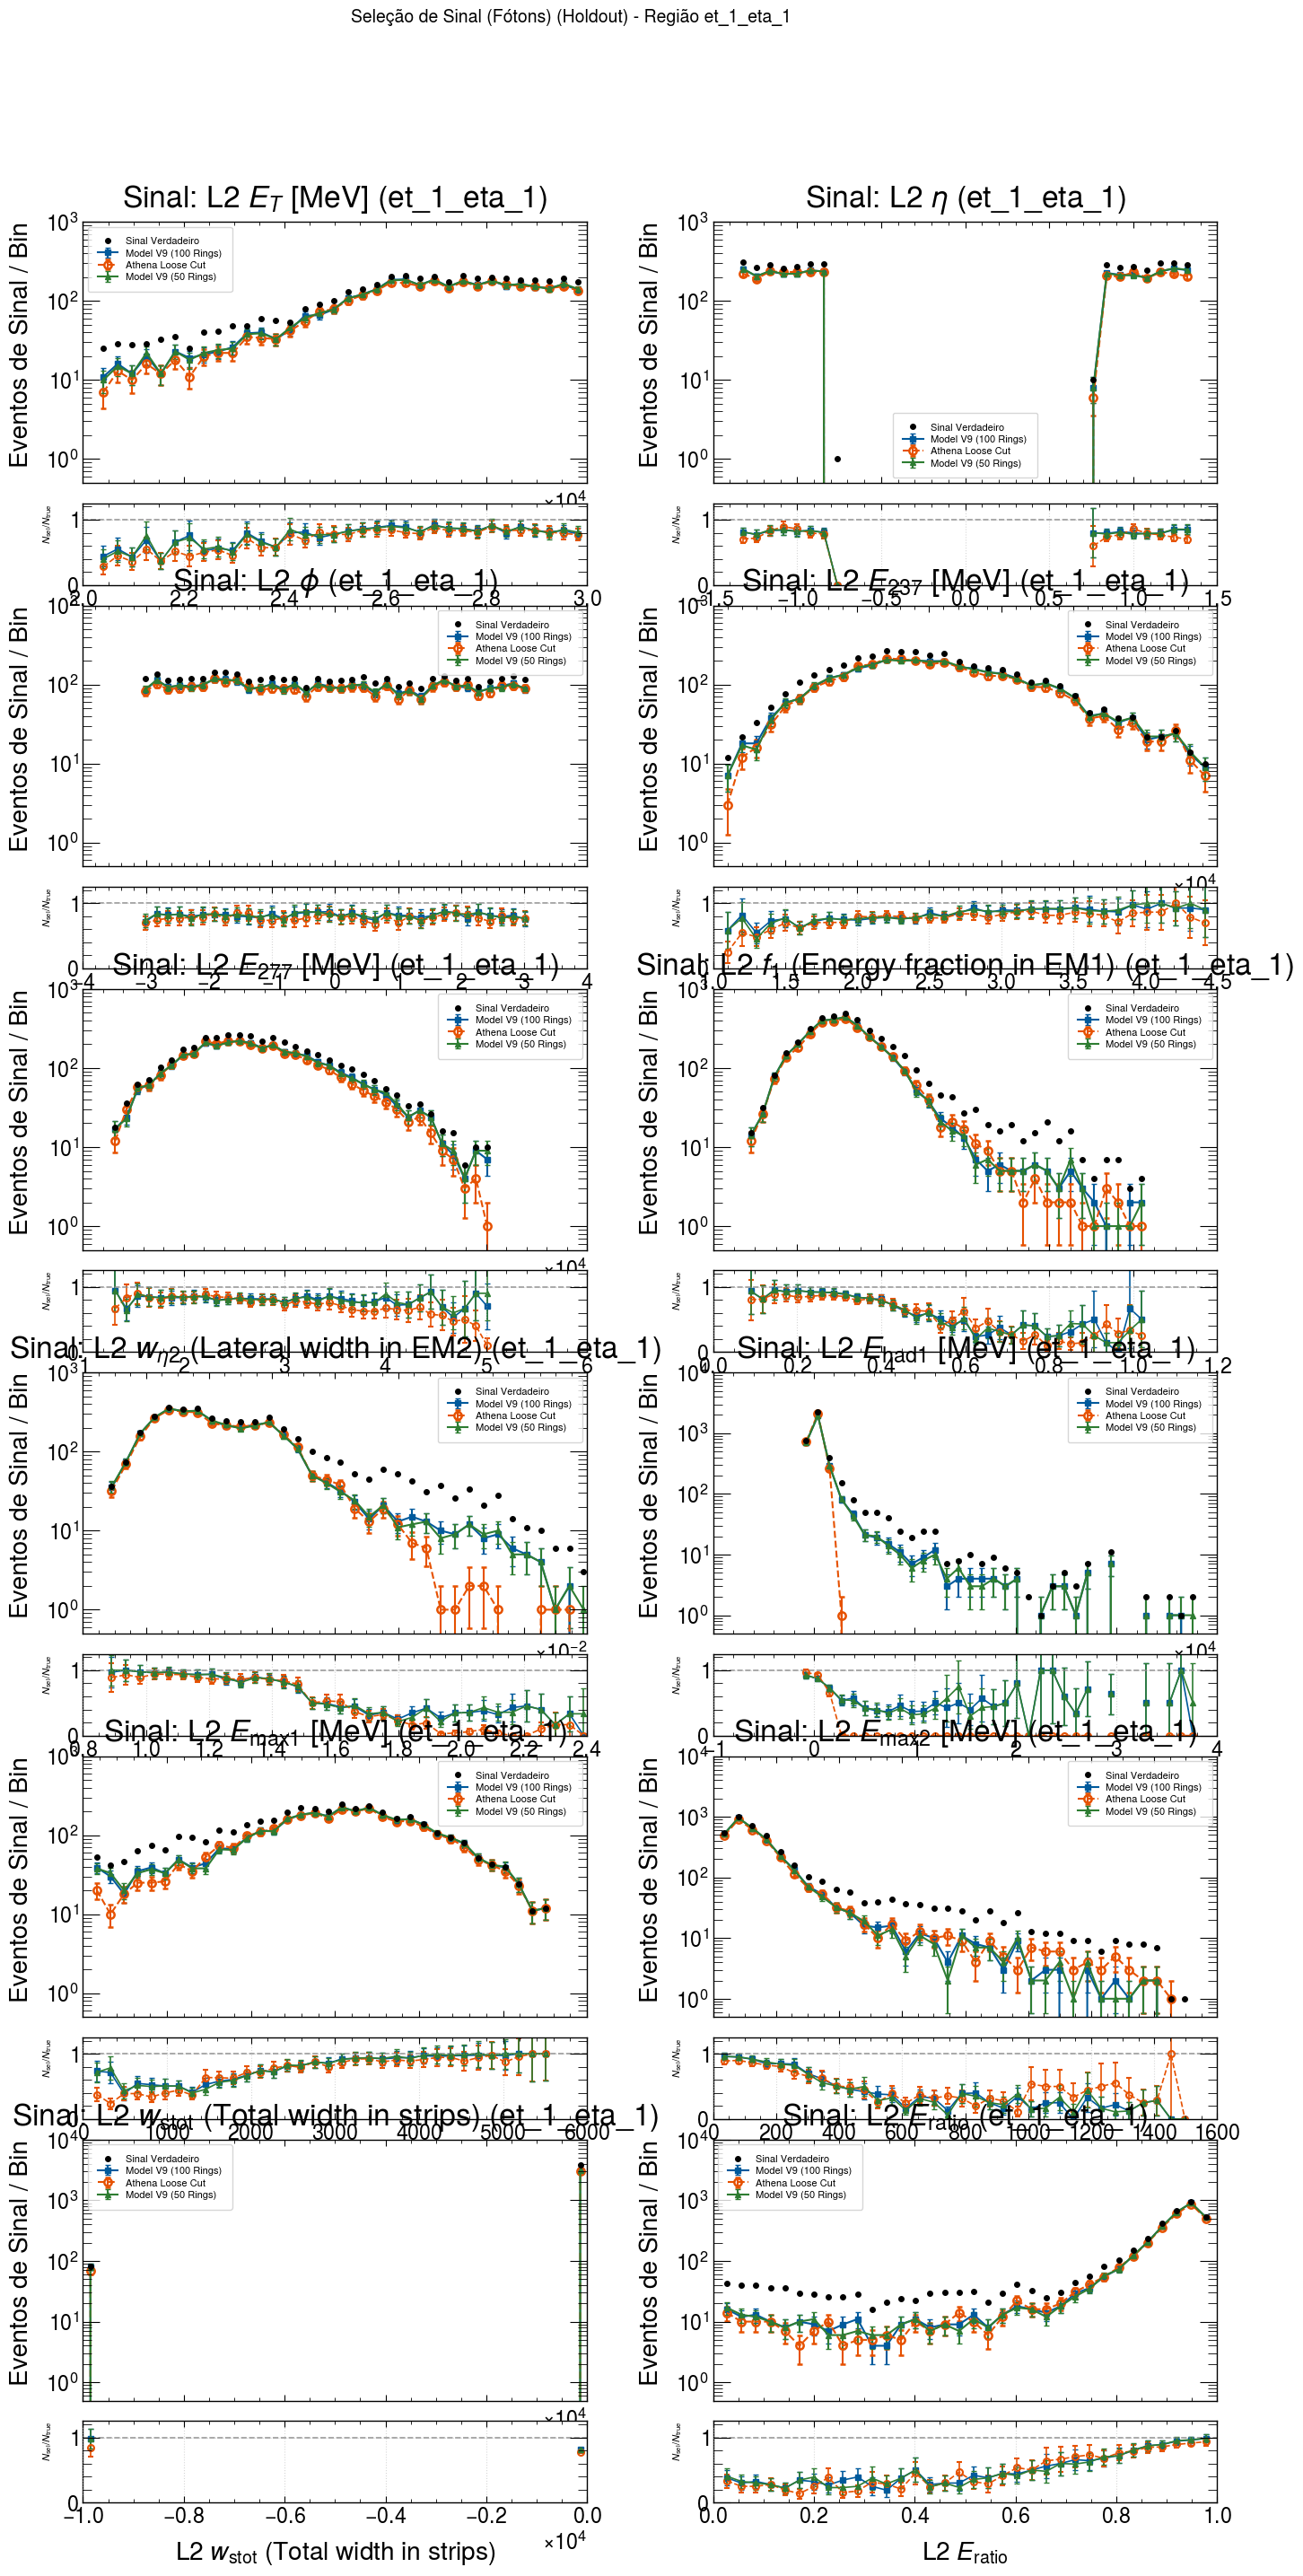

In [14]:
if not sig_ks_df.empty:
    print(f"Distance Metrics vs True Signal (Photons) ({REGION_KEY}):")
    display(sig_ks_df)
    save_table(sig_ks_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_true_signal")

feature_plotter = FeatureDistributionPlotter(language=LANGUAGE)
fig_sig = feature_plotter.plot_and_export_all(
    plot_data=signal_plot_data,
    features_to_plot=valid_features_to_plot,
    output_dir=OUTPUT_DIR / "signal_selection",
    region_key=REGION_KEY,
    is_signal=True,
    log_y=LOG_Y_SECTION_6,
    plot_format=PLOT_FORMAT,
)

<a id="sec-5-3"></a>
### 5.3 Jet Leak in Signal Distributions & KL / JS Divergence Table (Hard Cut)
Visualizes the shower-shape distributions of background jets leaking into the signal selection (`test_labels == 0 & preds == 1`) against the True Background distribution, along with the lower bin-by-bin fake rate panel ($N_{\mathrm{sel}} / N_{\mathrm{true}}$):

Distance Metrics: Jet Leak in Signal vs True Background (Jets) (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty
0,trig_L2_calo_et,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,1446,0.014879,0.007658,0.005162,0.002339
1,trig_L2_calo_et,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.007262,0.002824,0.002486,0.000915
2,trig_L2_calo_et,True Background,Model V9 (50 Rings),Model V9 (50 Rings) vs True Background,10384,1514,0.017499,0.016189,0.006024,0.002073
3,trig_L2_calo_eta,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,1446,0.012319,0.004976,0.004409,0.001769
4,trig_L2_calo_eta,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.030171,0.004279,0.010992,0.001552
5,trig_L2_calo_eta,True Background,Model V9 (50 Rings),Model V9 (50 Rings) vs True Background,10384,1514,0.012133,0.004902,0.004330,0.001724
6,trig_L2_calo_phi,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,1446,0.011329,0.005574,0.004077,0.001937
7,trig_L2_calo_phi,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.003127,0.002125,0.001141,0.000769
8,trig_L2_calo_phi,True Background,Model V9 (50 Rings),Model V9 (50 Rings) vs True Background,10384,1514,0.009937,0.005534,0.003573,0.001917
9,trig_L2_calo_e237,True Background,Model V9 (100 Rings),Model V9 (100 Rings) vs True Background,10384,1446,0.055647,0.017799,0.018711,0.003331


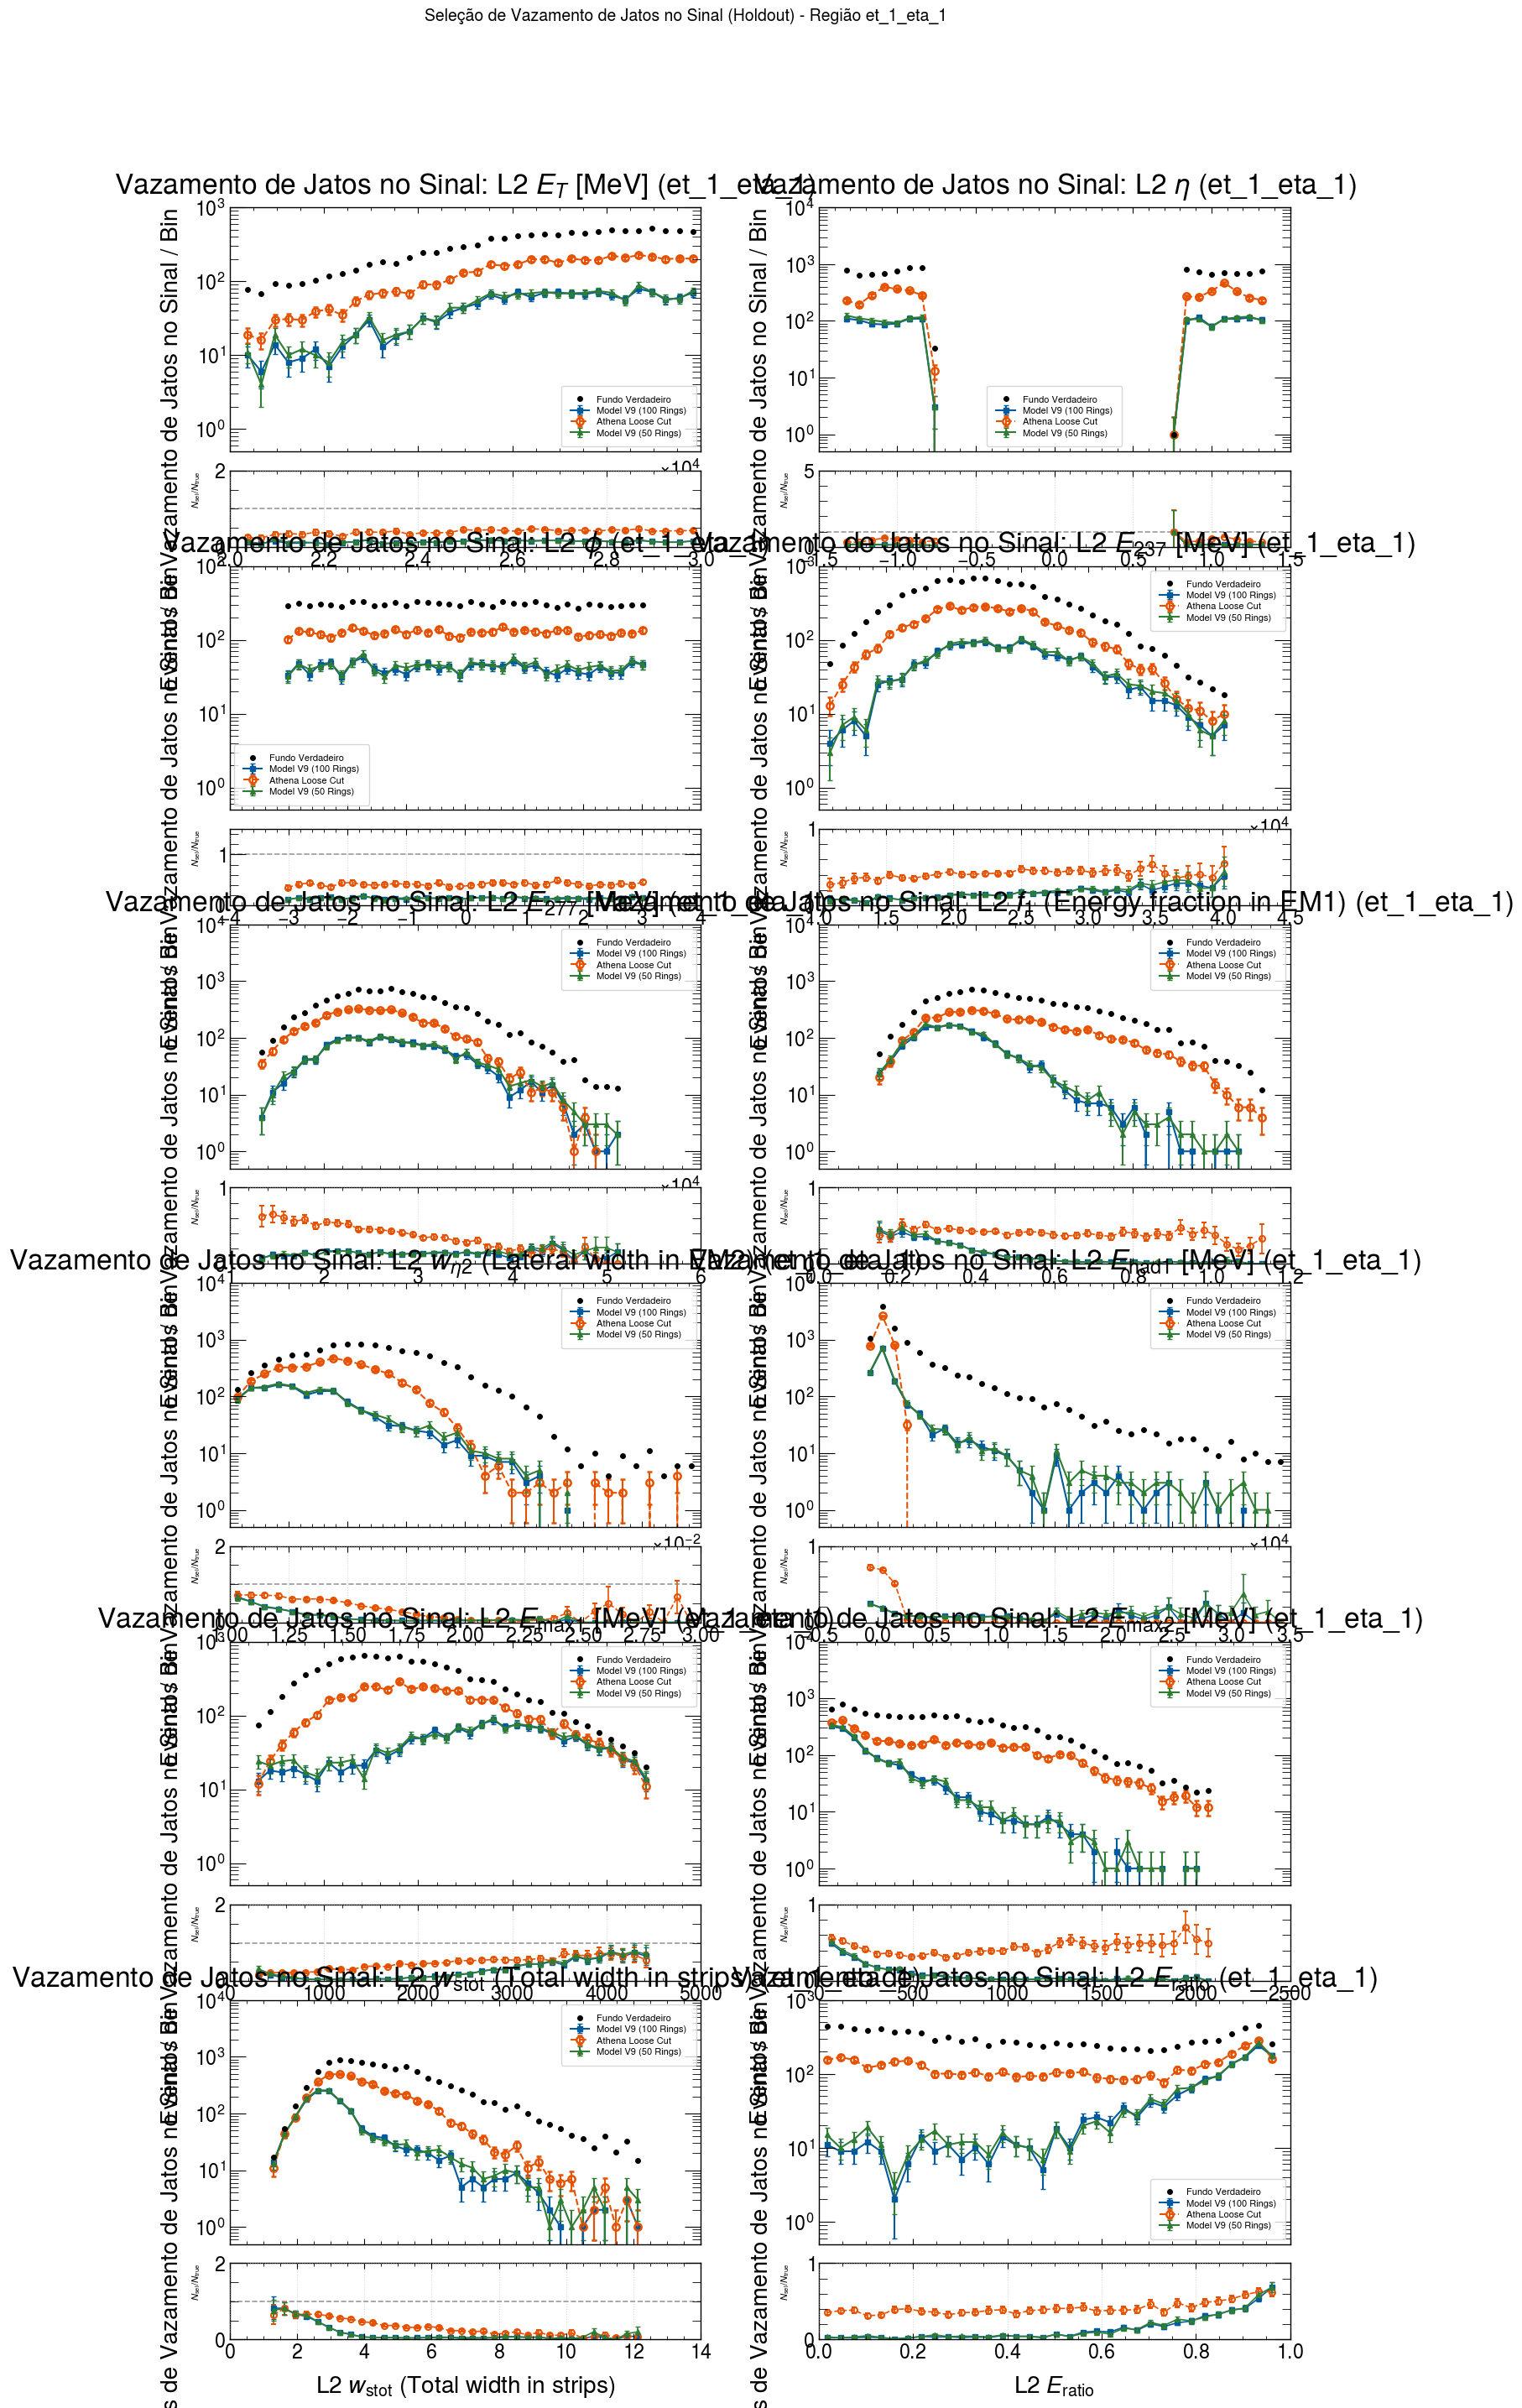

In [15]:
if not bg_ks_df.empty:
    print(f"Distance Metrics: Jet Leak in Signal vs True Background (Jets) ({REGION_KEY}):")
    display(bg_ks_df)
    save_table(bg_ks_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_true_background")

fig_bg = feature_plotter.plot_and_export_all(
    plot_data=background_plot_data,
    features_to_plot=valid_features_to_plot,
    output_dir=OUTPUT_DIR / "background_selection",
    region_key=REGION_KEY,
    is_signal=False,
    log_y=LOG_Y_SECTION_6,
    plot_format=PLOT_FORMAT,
)


<a id="sec-5-4"></a>
### 5.4 Precomputation of Histograms & KL / JS Divergences (Pileup-Corrected $T(\mu)$ Selections)
Replicates the feature distribution and KL / JS divergence evaluation using event selections determined by the dynamic pileup threshold $T(\mu) = a\mu + b$:

In [16]:
models_to_plot_pileup = [
    {
        "name": f"{MODEL_1_ALIAS} [T(mu)]",
        "preds": preds_pileup_1,
        "is_ml": True,
        "color": "#005A9C",
        "marker": "s",
    },
    {
        "name": ATHENA_ALIAS,
        "preds": cut_res.preds_strategy2,
        "is_ml": False,
        "color": "#E65100",
        "marker": "o",
    },
]

if ENABLE_MODEL2_COMPARISON and preds_pileup_2 is not None:
    models_to_plot_pileup.append({
        "name": f"{MODEL_2_ALIAS} [T(mu)]",
        "preds": preds_pileup_2,
        "is_ml": True,
        "color": "#2E7D32",
        "marker": "^",
    })

print("Precomputing feature distributions and KL / JS divergences for Pileup-Corrected selections vs True Data...")

signal_plot_data_pileup = {}
background_plot_data_pileup = {}

for feat_name in valid_features_to_plot:
    values = extract_feature_values(test_features, feature_names, feat_name)
    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name

    # 1. Signal Histogram Precomputations
    val_true_sig = values[test_labels == 1]
    val_true_sig = val_true_sig[np.isfinite(val_true_sig)]
    low_sig = np.percentile(val_true_sig, 0.5)
    high_sig = np.percentile(val_true_sig, 99.5)
    bins_sig = np.linspace(low_sig, high_sig, 35)
    bin_centers_sig = 0.5 * (bins_sig[:-1] + bins_sig[1:])
    counts_true_sig, _ = np.histogram(val_true_sig, bins=bins_sig)

    model_sig_data_pileup = []
    for m in models_to_plot_pileup:
        val_m_sig = values[(test_labels == 1) & (m["preds"] == 1)]
        val_m_sig = val_m_sig[np.isfinite(val_m_sig)]
        counts_m_sig, _ = np.histogram(val_m_sig, bins=bins_sig)
        model_sig_data_pileup.append({
            "name": m["name"],
            "counts": counts_m_sig,
            "errors": np.sqrt(counts_m_sig),
            "is_ml": m["is_ml"],
            "color": m["color"],
            "marker": m["marker"],
            "label": m["name"],
        })

    signal_plot_data_pileup[feat_name] = {
        "display_title": display_title,
        "bin_centers": bin_centers_sig,
        "true_counts": counts_true_sig,
        "true_n": len(val_true_sig),
        "models": model_sig_data_pileup,
    }

    # 2. Jet Leak in Signal Precomputations (test_labels == 0 & preds == 1)
    val_true_bg = values[test_labels == 0]
    val_true_bg = val_true_bg[np.isfinite(val_true_bg)]
    low_bg = np.percentile(val_true_bg, 0.5)
    high_bg = np.percentile(val_true_bg, 99.5)
    bins_bg = np.linspace(low_bg, high_bg, 35)
    bin_centers_bg = 0.5 * (bins_bg[:-1] + bins_bg[1:])
    counts_true_bg, _ = np.histogram(val_true_bg, bins=bins_bg)

    model_bg_data_pileup = []
    for m in models_to_plot_pileup:
        val_m_bg = values[(test_labels == 0) & (m["preds"] == 1)]
        val_m_bg = val_m_bg[np.isfinite(val_m_bg)]
        counts_m_bg, _ = np.histogram(val_m_bg, bins=bins_bg)
        model_bg_data_pileup.append({
            "name": m["name"],
            "counts": counts_m_bg,
            "errors": np.sqrt(counts_m_bg),
            "is_ml": m["is_ml"],
            "color": m["color"],
            "marker": m["marker"],
            "label": m["name"],
        })

    background_plot_data_pileup[feat_name] = {
        "display_title": display_title,
        "bin_centers": bin_centers_bg,
        "true_counts": counts_true_bg,
        "true_n": len(val_true_bg),
        "models": model_bg_data_pileup,
    }

strategies_dict_pileup = {m["name"]: m["preds"] for m in models_to_plot_pileup}
sig_ks_pileup_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict_pileup, reference_strategy=None, is_signal=True
)
bg_ks_pileup_df = dist_comparator.compare_strategies(
    test_features, feature_names, test_labels, valid_features_to_plot,
    strategies_dict_pileup, reference_strategy=None, is_signal=False
)


Precomputing feature distributions and KL / JS divergences for Pileup-Corrected selections vs True Data...


<a id="sec-5-5"></a>
### 5.5 Signal Feature Distributions & KL / JS Divergence Table ($T(\mu)$ Selection)

Distance Metrics vs True Signal (Photons) - Pileup Selection (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty
0,trig_L2_calo_et,True Signal,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Signal,3994,3255,0.009008,0.004346,0.003017,0.001326
1,trig_L2_calo_et,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.013618,0.005744,0.004515,0.001753
2,trig_L2_calo_et,True Signal,Model V9 (50 Rings) [T(mu)],Model V9 (50 Rings) [T(mu)] vs True Signal,3994,3269,0.009452,0.005377,0.003134,0.001525
3,trig_L2_calo_eta,True Signal,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Signal,3994,3255,0.000490,0.001646,0.000176,0.000593
4,trig_L2_calo_eta,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.002597,0.002715,0.000936,0.000969
5,trig_L2_calo_eta,True Signal,Model V9 (50 Rings) [T(mu)],Model V9 (50 Rings) [T(mu)] vs True Signal,3994,3269,0.000582,0.001709,0.000210,0.000605
6,trig_L2_calo_phi,True Signal,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Signal,3994,3255,0.001026,0.002684,0.000369,0.000963
7,trig_L2_calo_phi,True Signal,Athena Loose Cut,Athena Loose Cut vs True Signal,3994,3106,0.001909,0.002916,0.000688,0.001032
8,trig_L2_calo_phi,True Signal,Model V9 (50 Rings) [T(mu)],Model V9 (50 Rings) [T(mu)] vs True Signal,3994,3269,0.000933,0.002375,0.000336,0.000850
9,trig_L2_calo_e237,True Signal,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Signal,3994,3255,0.004364,0.003412,0.001567,0.001211


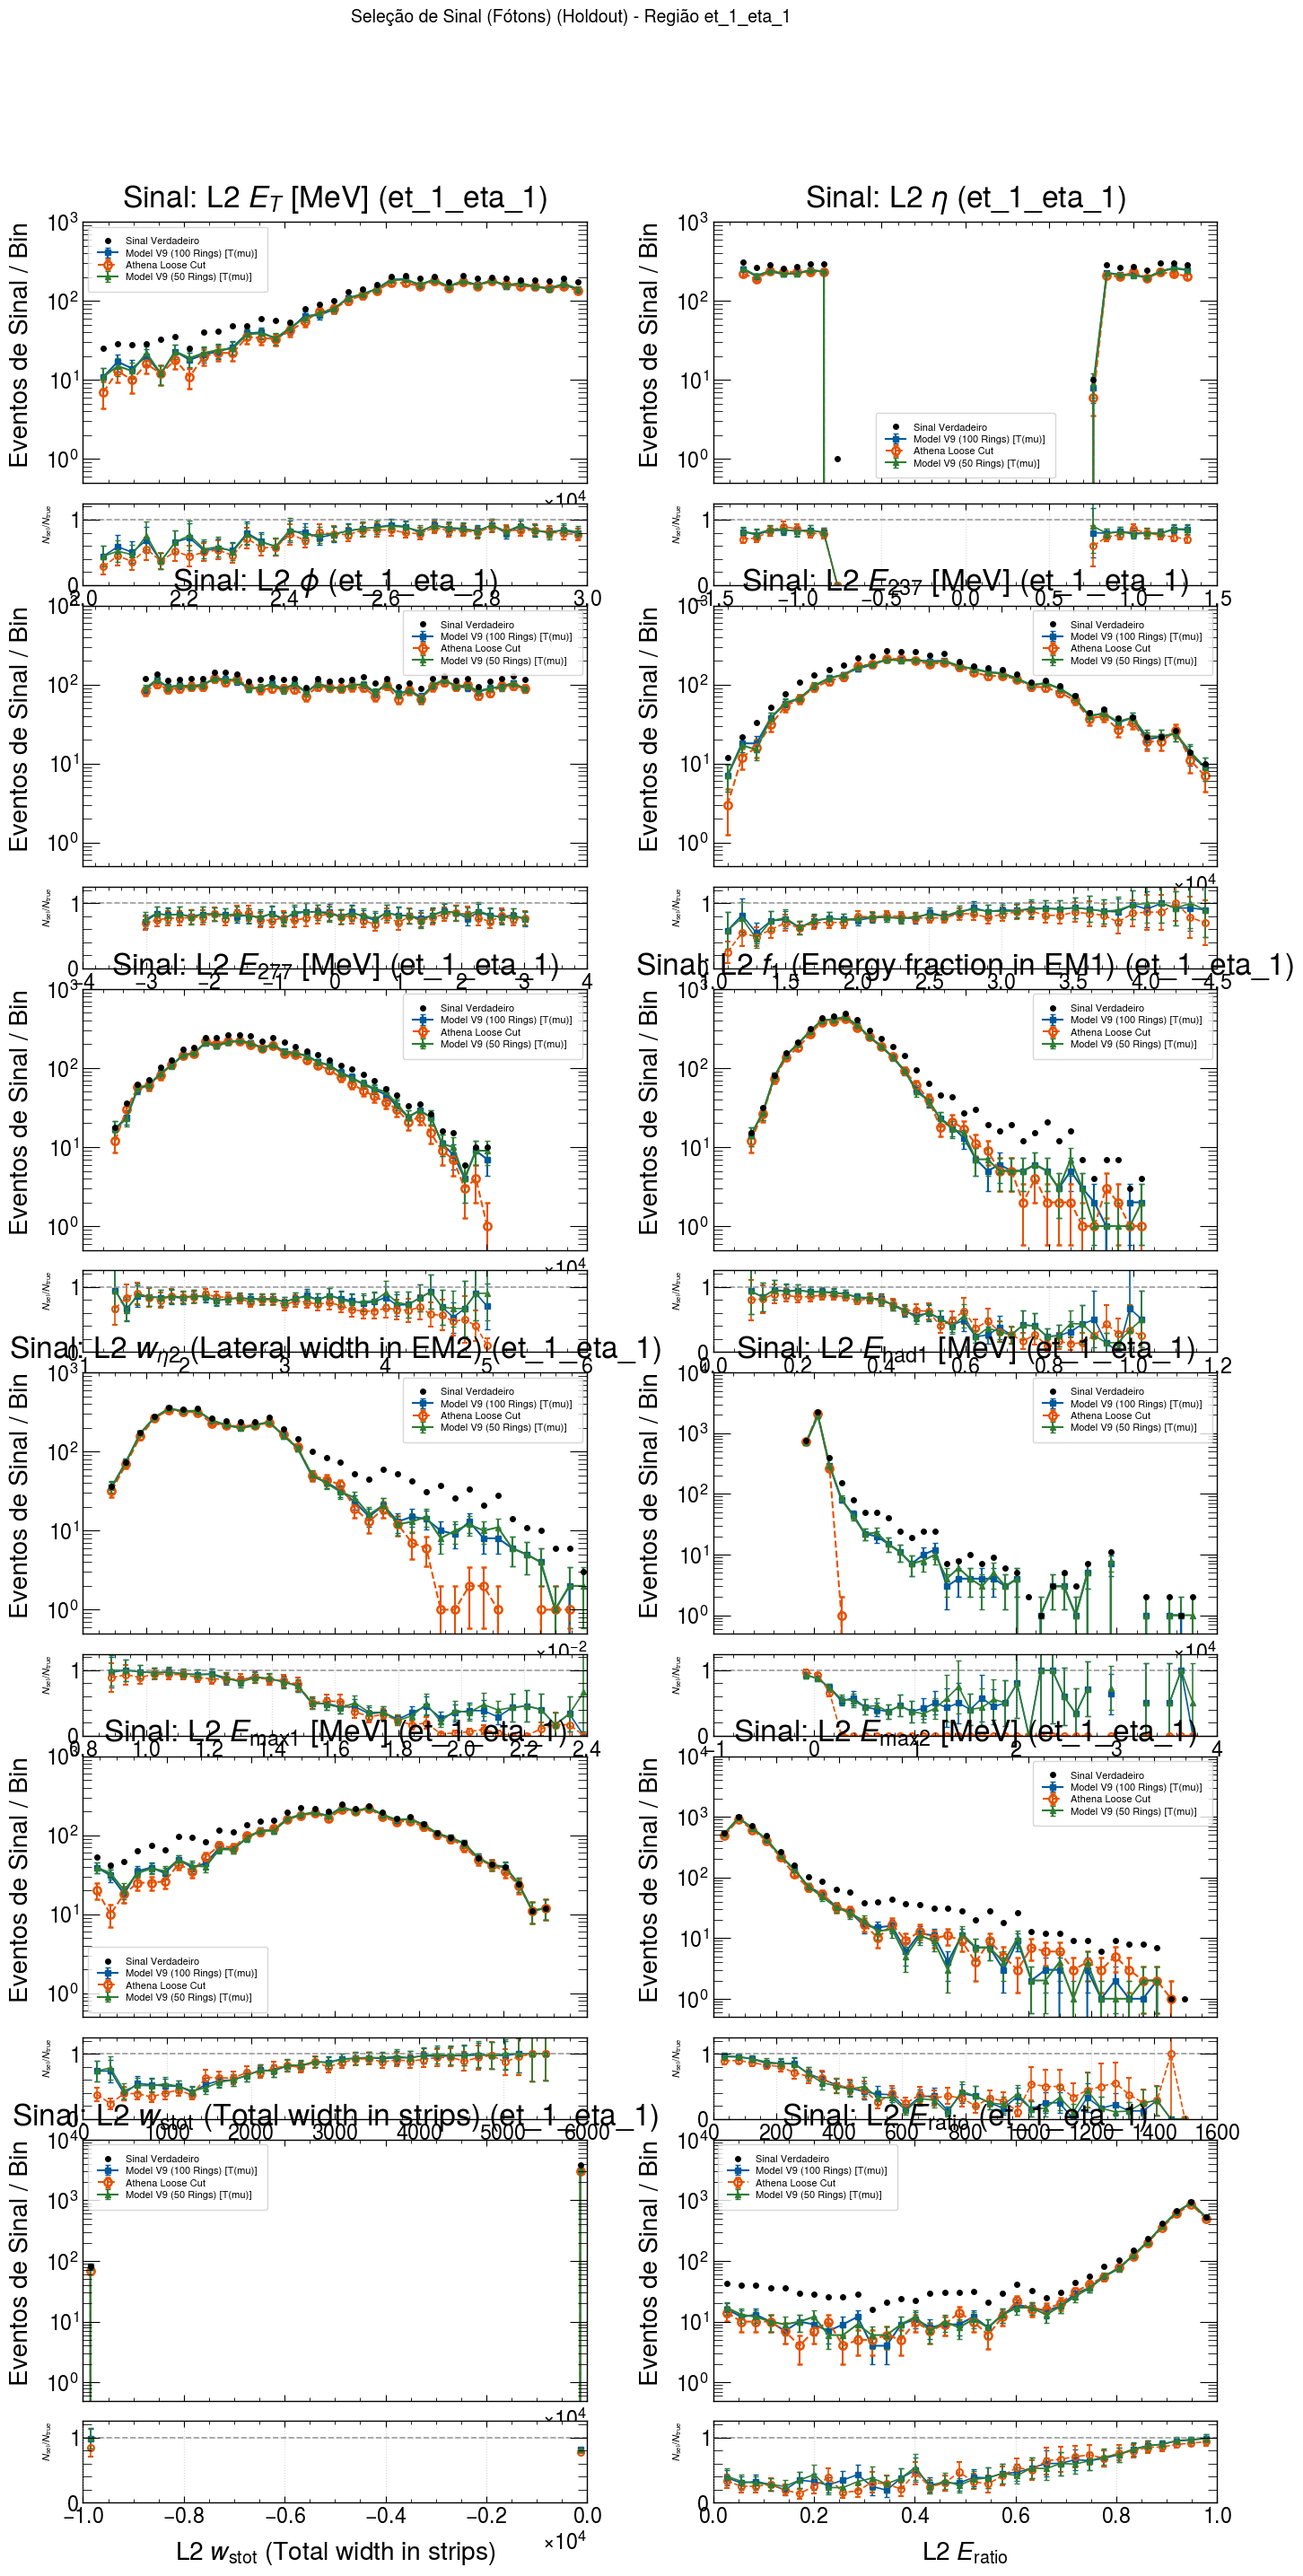

In [17]:
if not sig_ks_pileup_df.empty:
    print(f"Distance Metrics vs True Signal (Photons) - Pileup Selection ({REGION_KEY}):")
    display(sig_ks_pileup_df)
    save_table(sig_ks_pileup_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_true_signal_pileup")

fig_sig_pileup = feature_plotter.plot_and_export_all(
    plot_data=signal_plot_data_pileup,
    features_to_plot=valid_features_to_plot,
    output_dir=OUTPUT_DIR / "signal_selection_pileup",
    region_key=REGION_KEY,
    is_signal=True,
    log_y=LOG_Y_SECTION_6,
    plot_format=PLOT_FORMAT,
)


<a id="sec-5-6"></a>
### 5.6 Jet Leak in Signal Distributions & KL / JS Divergence Table ($T(\mu)$ Selection)

Distance Metrics: Jet Leak in Signal vs True Background (Jets) - Pileup Selection (et_1_eta_1):


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,KL Divergence,KL Uncertainty,JS Divergence,JS Uncertainty
0,trig_L2_calo_et,True Background,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Background,10384,1486,0.014152,0.013216,0.004890,0.002137
1,trig_L2_calo_et,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.007262,0.002824,0.002486,0.000915
2,trig_L2_calo_et,True Background,Model V9 (50 Rings) [T(mu)],Model V9 (50 Rings) [T(mu)] vs True Background,10384,1585,0.015780,0.007079,0.005456,0.002182
3,trig_L2_calo_eta,True Background,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Background,10384,1486,0.010944,0.005424,0.003921,0.001893
4,trig_L2_calo_eta,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.030171,0.004279,0.010992,0.001552
5,trig_L2_calo_eta,True Background,Model V9 (50 Rings) [T(mu)],Model V9 (50 Rings) [T(mu)] vs True Background,10384,1585,0.010508,0.004069,0.003740,0.001430
6,trig_L2_calo_phi,True Background,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Background,10384,1486,0.010306,0.005370,0.003690,0.001867
7,trig_L2_calo_phi,True Background,Athena Loose Cut,Athena Loose Cut vs True Background,10384,4309,0.003127,0.002125,0.001141,0.000769
8,trig_L2_calo_phi,True Background,Model V9 (50 Rings) [T(mu)],Model V9 (50 Rings) [T(mu)] vs True Background,10384,1585,0.010097,0.005443,0.003628,0.001907
9,trig_L2_calo_e237,True Background,Model V9 (100 Rings) [T(mu)],Model V9 (100 Rings) [T(mu)] vs True Background,10384,1486,0.054462,0.013786,0.018482,0.003482


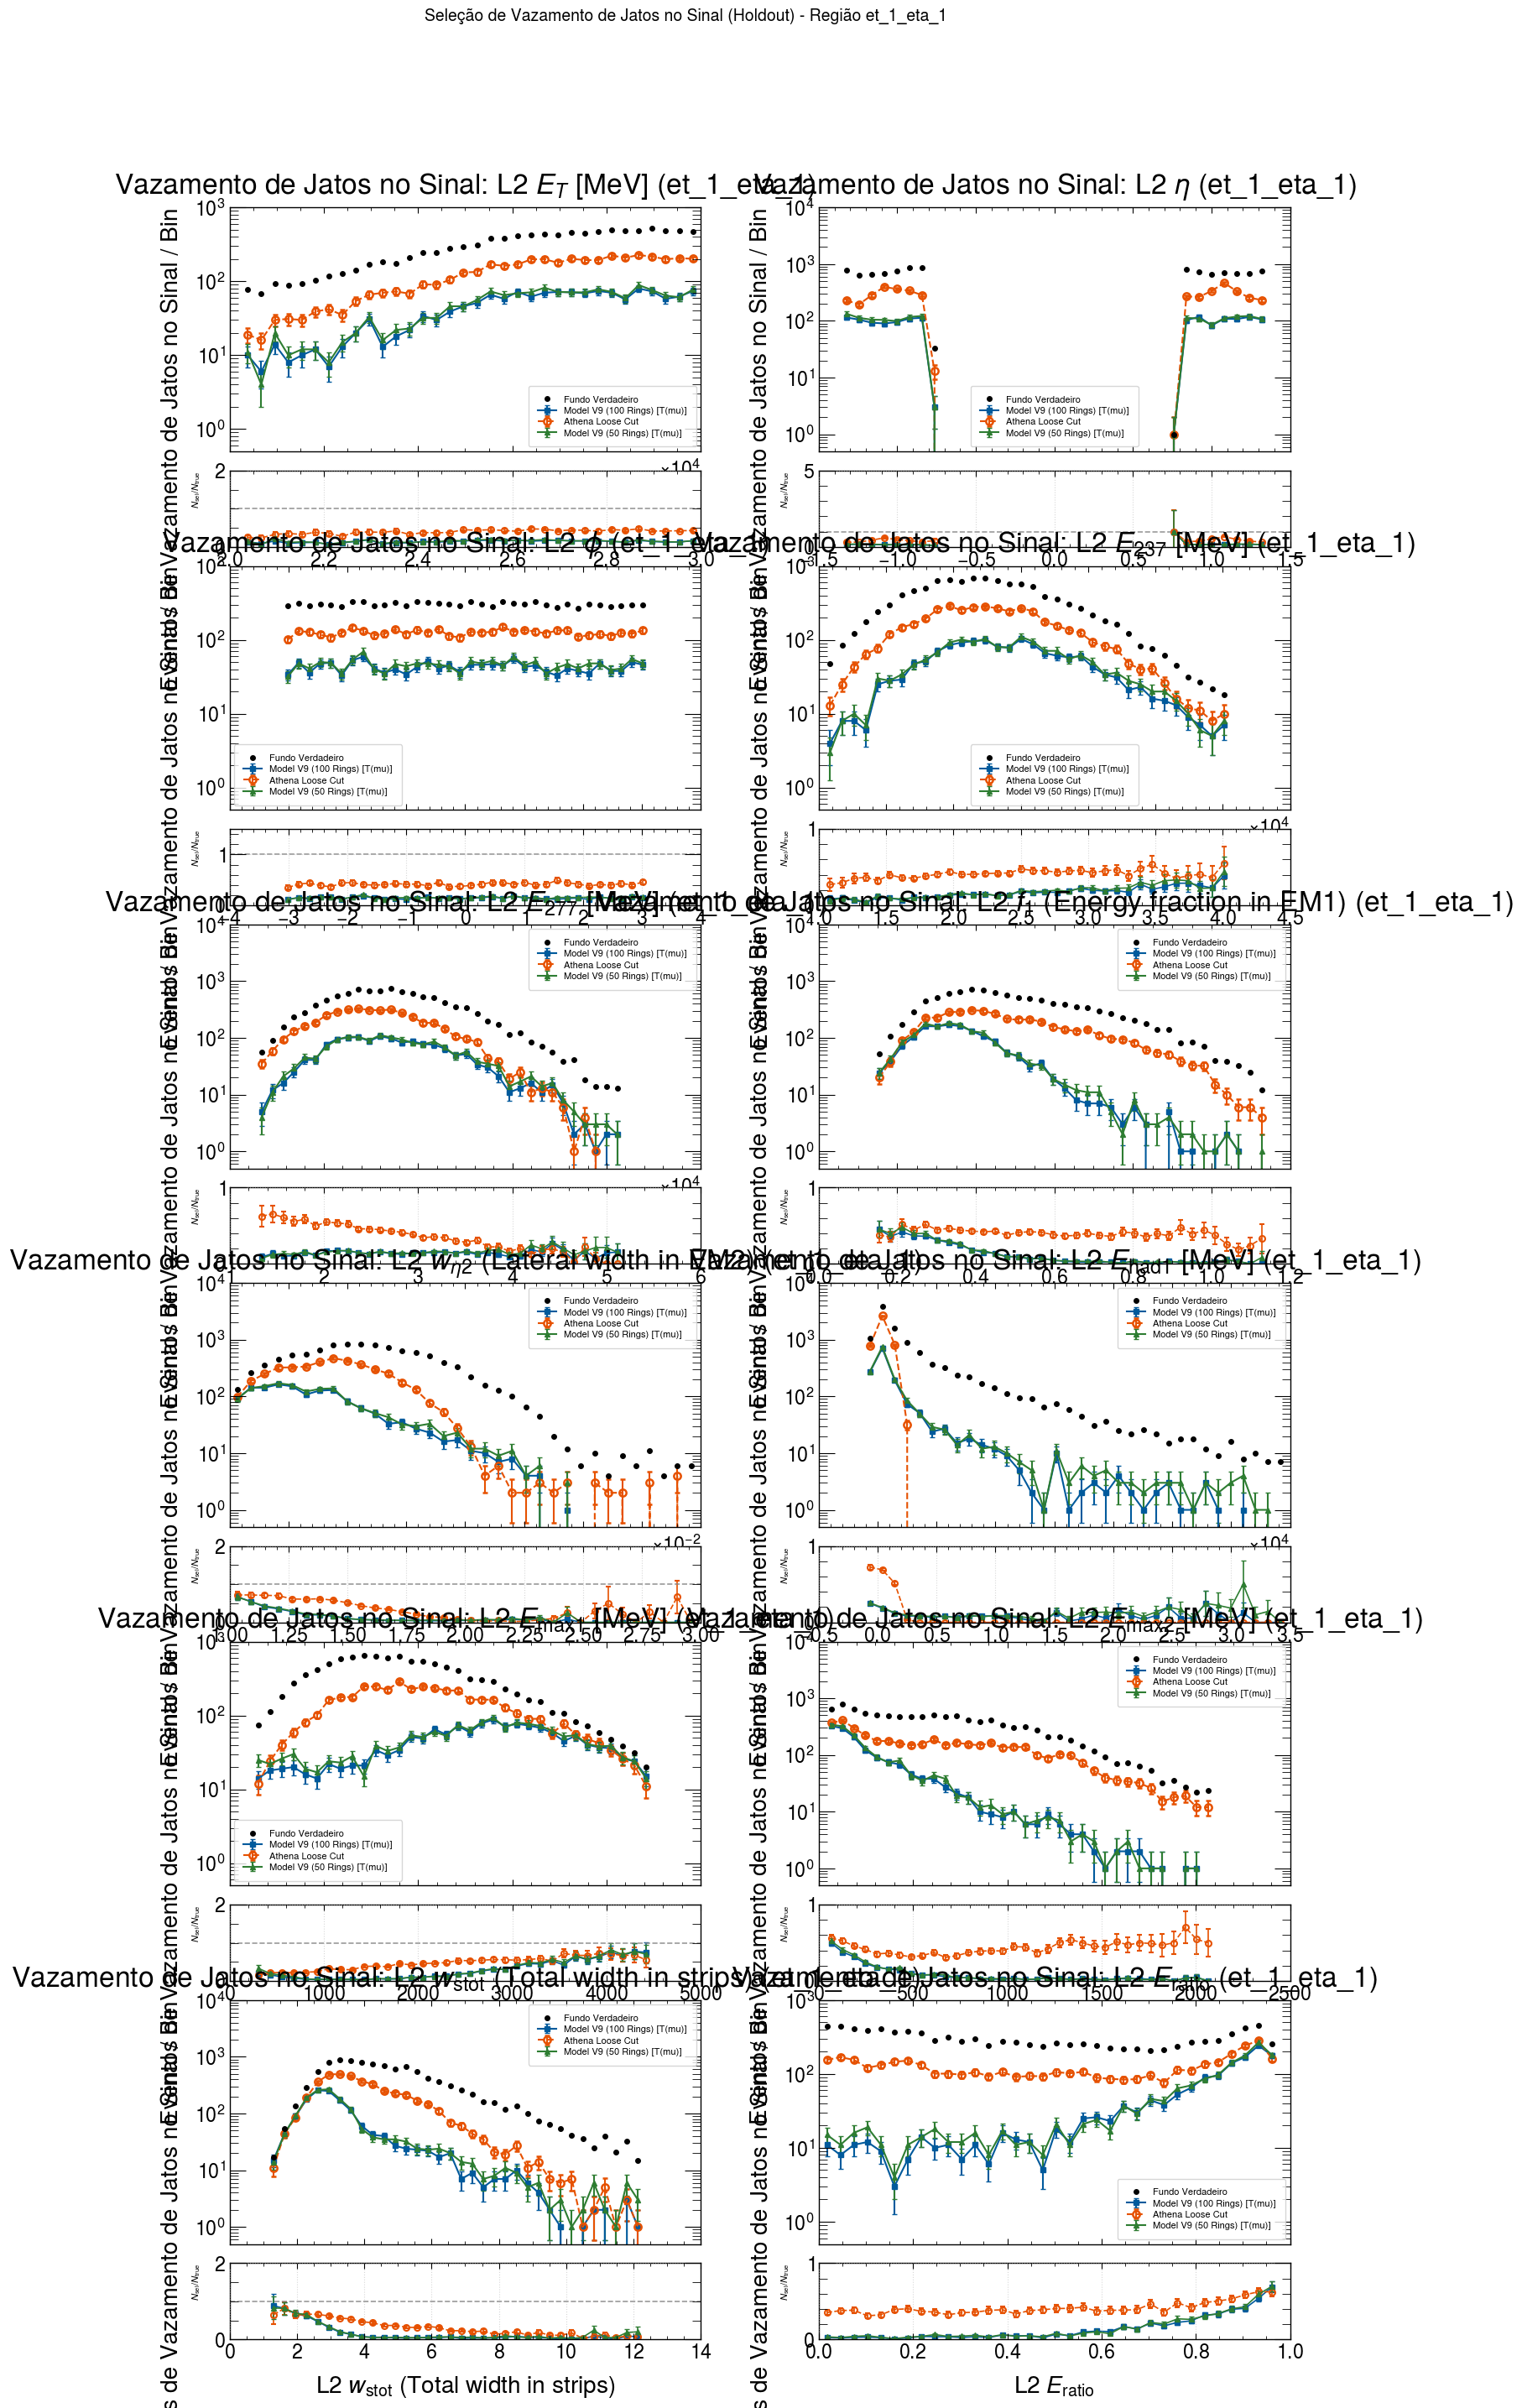

In [18]:
if not bg_ks_pileup_df.empty:
    print(f"Distance Metrics: Jet Leak in Signal vs True Background (Jets) - Pileup Selection ({REGION_KEY}):")
    display(bg_ks_pileup_df)
    save_table(bg_ks_pileup_df, TABLES_DIR, REGION_KEY, "distance_metrics_vs_true_background_pileup")

fig_bg_pileup = feature_plotter.plot_and_export_all(
    plot_data=background_plot_data_pileup,
    features_to_plot=valid_features_to_plot,
    output_dir=OUTPUT_DIR / "background_selection_pileup",
    region_key=REGION_KEY,
    is_signal=False,
    log_y=LOG_Y_SECTION_6,
    plot_format=PLOT_FORMAT,
)
